# 04 · Three-Phase Training
**Intel Scene Classification with a CNN Trained From Scratch (TensorFlow / Keras)**  
*Section 4* · MSc Data Science project · Dr. Spoorthi H S

**In this notebook**
- Custom cosine-annealing learning-rate schedule with linear warmup
- Label-smoothed categorical cross-entropy (ε = 0.1) and AdamW
- Phase 1 → 2 → 3 with decreasing learning rates, checkpointing and early stopping
- Best validation accuracy 90.60 %

> **How to use these notebooks.** The outputs below come from one complete training run on a Kaggle Tesla T4 GPU. Each part builds on objects created earlier (configuration, data pipelines, the trained model), so the part notebooks are for reading and review. To reproduce the results, run [`00_full_pipeline_run_all.ipynb`](00_full_pipeline_run_all.ipynb) top to bottom.

[← Model Design: DeepSceneNet](03_model_architecture.ipynb) · [Evaluation, Error Analysis & Grad-CAM →](05_evaluation_and_explainability.ipynb)

---

---
## 4️⃣ Model Training
### 4.1 Custom Learning-Rate Schedule (Cosine Annealing with Warmup)

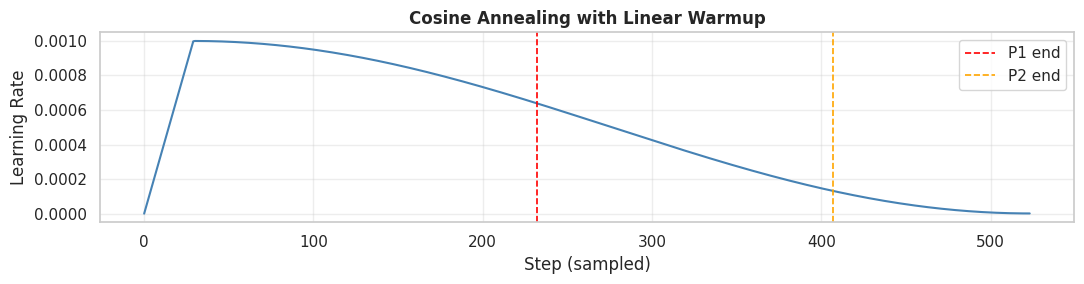

In [ ]:
class CosineAnnealingWarmup(keras.optimizers.schedules.LearningRateSchedule):
    """Linear warmup for `warmup_steps`, then cosine annealing to `min_lr`."""
    def __init__(self, base_lr, total_steps, warmup_steps, min_lr=1e-6):
        super().__init__()
        self.base_lr      = base_lr
        self.total_steps  = total_steps
        self.warmup_steps = warmup_steps
        self.min_lr       = min_lr

    def __call__(self, step):
        step        = tf.cast(step, tf.float32)
        warmup_lr   = self.base_lr * (step / float(self.warmup_steps))
        cos_factor  = 0.5 * (1.0 + tf.cos(
            np.pi * (step - self.warmup_steps) /
            float(self.total_steps - self.warmup_steps)
        ))
        cosine_lr   = self.min_lr + (self.base_lr - self.min_lr) * cos_factor
        return tf.where(step < self.warmup_steps, warmup_lr, cosine_lr)

    def get_config(self):
        return dict(base_lr=self.base_lr, total_steps=self.total_steps,
                    warmup_steps=self.warmup_steps, min_lr=self.min_lr)

# ─── Visualise schedule ───────────────────────────────────────────────────────
total_steps   = STEPS_PER_EPOCH * (CFG["EPOCHS_P1"]+CFG["EPOCHS_P2"]+CFG["EPOCHS_P3"])
warmup_steps  = STEPS_PER_EPOCH * CFG["WARMUP_EPOCHS"]
sched_preview = CosineAnnealingWarmup(1e-3, total_steps, warmup_steps)
xs            = np.arange(total_steps)
ys            = [float(sched_preview(x)) for x in xs[::max(1,total_steps//500)]]

fig, ax = plt.subplots(figsize=(11,3))
ax.plot(ys, color="steelblue", lw=1.5)
ax.axvline(len(ys)*STEPS_PER_EPOCH*CFG["EPOCHS_P1"]//total_steps,
           color="red",   ls="--", lw=1.2, label="P1 end")
ax.axvline(len(ys)*STEPS_PER_EPOCH*(CFG["EPOCHS_P1"]+CFG["EPOCHS_P2"])//total_steps,
           color="orange",ls="--", lw=1.2, label="P2 end")
ax.set_xlabel("Step (sampled)"); ax.set_ylabel("Learning Rate")
ax.set_title("Cosine Annealing with Linear Warmup", fontsize=12, fontweight="bold")
ax.legend(); ax.grid(alpha=0.35)
plt.tight_layout()
plt.savefig("lr_schedule.png", dpi=150, bbox_inches="tight"); plt.show()


### 4.2 Loss Function: Label-Smoothed Categorical Cross-Entropy

In [ ]:
class LabelSmoothingCCE(keras.losses.Loss):
    """Categorical cross-entropy with label smoothing.
    Accepts both hard integer labels and soft one-hot labels.
    """
    def __init__(self, smoothing=CFG["LABEL_SMOOTH"], **kwargs):
        super().__init__(**kwargs)
        self.smoothing = smoothing

    def call(self, y_true, y_pred):
        y_pred   = tf.cast(y_pred, tf.float32)          # ensure float32
        y_pred   = tf.clip_by_value(y_pred, 1e-7, 1.0)
        n_cls    = tf.cast(tf.shape(y_pred)[-1], tf.float32)

        # Handle both sparse (1-D) and one-hot (2-D) y_true
        is_1d = tf.equal(tf.rank(y_true), 1)
        last_dim_mismatch = tf.not_equal(tf.shape(y_true)[-1],
                                          tf.cast(n_cls, tf.int32))
        needs_one_hot = tf.logical_or(is_1d, last_dim_mismatch)
        y_true = tf.cond(
            needs_one_hot,
            lambda: tf.one_hot(tf.cast(y_true, tf.int32),
                               depth=tf.cast(n_cls, tf.int32),
                               dtype=tf.float32),
            lambda: tf.cast(y_true, tf.float32))

        y_smooth = y_true * (1.0 - self.smoothing) + self.smoothing / n_cls
        return -tf.reduce_mean(tf.reduce_sum(y_smooth * tf.math.log(y_pred),
                                              axis=-1))

    def get_config(self):
        cfg = super().get_config()
        cfg["smoothing"] = self.smoothing
        return cfg

print(f"Label smoothing factor : {CFG['LABEL_SMOOTH']}")
loss_fn = LabelSmoothingCCE(smoothing=CFG["LABEL_SMOOTH"])


Label smoothing factor : 0.1


### 4.3 Callbacks

In [ ]:
def get_callbacks(monitor="val_accuracy", mode="max"):
    return [
        callbacks.ModelCheckpoint(
            CFG["CKPT_PATH"],
            monitor=monitor, mode=mode,
            save_best_only=True, verbose=1),

        callbacks.EarlyStopping(
            monitor=monitor, mode=mode,
            patience=12, restore_best_weights=True, verbose=1),

        # Removed ReduceLROnPlateau as it conflicts with LearningRateSchedule
        # callbacks.ReduceLROnPlateau(
        #     monitor="val_loss", factor=0.4,
        #     patience=5, min_lr=1e-7, verbose=1),

        callbacks.TensorBoard(log_dir="./tb_logs", histogram_freq=1),

        callbacks.CSVLogger("training_log.csv", append=True),
    ]

print("Callbacks defined: ModelCheckpoint, EarlyStopping, TensorBoard, CSVLogger")
print("Note: ReduceLROnPlateau is removed as it conflicts with custom LR schedule.")


Callbacks defined: ModelCheckpoint, EarlyStopping, TensorBoard, CSVLogger
Note: ReduceLROnPlateau is removed as it conflicts with custom LR schedule.


### 4.4 Phase 1 — Full Network, High LR with Warmup

In [ ]:
# ─── Phase 1: Build & train from scratch (High LR + Cosine Warmup) ──────────
tf.keras.backend.clear_session()
tf.random.set_seed(SEED)

# Re-enable mixed precision after clear_session (policy is global, persists)
tf.keras.mixed_precision.set_global_policy("mixed_float16")

model = build_deepscenenet()

STEPS_PER_EPOCH = len(tr_p) // CFG["BATCH_SIZE"]
IMG_SIZE   = CFG["IMG_SIZE"]
AUTOTUNE   = CFG["AUTOTUNE"]
BATCH_SIZE = CFG["BATCH_SIZE"]

steps_p1    = STEPS_PER_EPOCH * CFG["EPOCHS_P1"]
warmup_p1   = STEPS_PER_EPOCH * CFG["WARMUP_EPOCHS"]
lr_sched_p1 = CosineAnnealingWarmup(CFG["LR_P1"], steps_p1, warmup_p1)

model.compile(
    optimizer=optimizers.Adam(learning_rate=lr_sched_p1),
    loss=loss_fn,
    metrics=[keras.metrics.CategoricalAccuracy(name="accuracy")]
)

print("=" * 65)
print(f"  PHASE 1 — Training from scratch  "
      f"(max {CFG['EPOCHS_P1']} epochs, LR={CFG['LR_P1']})")
print(f"  Steps/epoch : {STEPS_PER_EPOCH}  |  Batch : {CFG['BATCH_SIZE']}")
print("=" * 65)

history_p1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=CFG["EPOCHS_P1"],
    callbacks=get_callbacks(),
    verbose=1,
)


  PHASE 1 — Training from scratch  (max 40 epochs, LR=0.001)
  Steps/epoch : 93  |  Batch : 128
Epoch 1/40


I0000 00:00:1773799621.595417     133 cuda_dnn.cc:529] Loaded cuDNN version 91002


93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 689ms/step - accuracy: 0.2460 - loss: 4.3445
Epoch 1: val_accuracy improved from -inf to 0.19991, saving model to /kaggle/working/best_cnn_model.keras
93/93 ━━━━━━━━━━━━━━━━━━━━ 105s 803ms/step - accuracy: 0.2468 - loss: 4.3427 - val_accuracy: 0.1999 - val_loss: 4.1770
Epoch 2/40
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 722ms/step - accuracy: 0.4424 - loss: 3.9377
Epoch 2: val_accuracy improved from 0.19991 to 0.36847, saving model to /kaggle/working/best_cnn_model.keras
93/93 ━━━━━━━━━━━━━━━━━━━━ 75s 808ms/step - accuracy: 0.4425 - loss: 3.9373 - val_accuracy: 0.3685 - val_loss: 4.0918
Epoch 3/40
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 744ms/step - accuracy: 0.5050 - loss: 3.7678
Epoch 3: val_accuracy improved from 0.36847 to 0.46914, saving model to /kaggle/working/best_cnn_model.keras
93/93 ━━━━━━━━━━━━━━━━━━━━ 78s 829ms/step - accuracy: 0.5051 - loss: 3.7675 - val_accuracy: 0.4691 - val_loss: 3.6176
Epoch 4/40
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 743ms/step - accuracy: 0.5624 - l

### 4.5 Phase 2 — Lower LR, Harder Convergence

In [ ]:
# ─── Phase 2: Load best weights from P1, lower LR ───────────────────────────
model.load_weights(CFG["CKPT_PATH"])

steps_p2    = STEPS_PER_EPOCH * CFG["EPOCHS_P2"]
lr_sched_p2 = CosineAnnealingWarmup(CFG["LR_P2"], steps_p2, warmup_steps=0)

model.compile(
    optimizer=optimizers.AdamW(learning_rate=lr_sched_p2,
                               weight_decay=CFG["L2_REG"]),
    loss=loss_fn,
    metrics=[keras.metrics.CategoricalAccuracy(name="accuracy"),
             keras.metrics.TopKCategoricalAccuracy(k=2, name="top2_acc")]
)

print("=" * 65)
print(f"  PHASE 2 — Lower LR fine-tuning  "
      f"(max {CFG['EPOCHS_P2']} epochs, LR={CFG['LR_P2']})")
print("=" * 65)

history_p2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=CFG["EPOCHS_P2"],
    callbacks=get_callbacks(),
    verbose=1,
)


  PHASE 2 — Lower LR fine-tuning  (max 30 epochs, LR=0.0002)
Epoch 1/30
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 757ms/step - accuracy: 0.7106 - loss: 2.1027 - top2_acc: 0.8904
Epoch 1: val_accuracy improved from -inf to 0.83191, saving model to /kaggle/working/best_cnn_model.keras
93/93 ━━━━━━━━━━━━━━━━━━━━ 111s 862ms/step - accuracy: 0.7108 - loss: 2.1023 - top2_acc: 0.8905 - val_accuracy: 0.8319 - val_loss: 1.6479 - val_top2_acc: 0.9478
Epoch 2/30
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 756ms/step - accuracy: 0.7327 - loss: 1.9867 - top2_acc: 0.8948
Epoch 2: val_accuracy did not improve from 0.83191
93/93 ━━━━━━━━━━━━━━━━━━━━ 77s 823ms/step - accuracy: 0.7328 - loss: 1.9864 - top2_acc: 0.8949 - val_accuracy: 0.7749 - val_loss: 1.6433 - val_top2_acc: 0.9198
Epoch 3/30
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 755ms/step - accuracy: 0.7260 - loss: 1.9069 - top2_acc: 0.8976
Epoch 3: val_accuracy did not improve from 0.83191
93/93 ━━━━━━━━━━━━━━━━━━━━ 77s 821ms/step - accuracy: 0.7261 - loss: 1.9067 - top2_acc: 0.8976 

### 4.6 Phase 3 — Final Fine Convergence

In [ ]:
# ─── Phase 3: Load best P2 weights, final fine convergence ──────────────────
model.load_weights(CFG["CKPT_PATH"])

steps_p3    = STEPS_PER_EPOCH * CFG["EPOCHS_P3"]
lr_sched_p3 = CosineAnnealingWarmup(CFG["LR_P3"], steps_p3, warmup_steps=0)

model.compile(
    optimizer=optimizers.AdamW(learning_rate=lr_sched_p3,
                               weight_decay=CFG["L2_REG"]),
    loss=loss_fn,
    metrics=[keras.metrics.CategoricalAccuracy(name="accuracy"),
             keras.metrics.TopKCategoricalAccuracy(k=2, name="top2_acc")]
)

print("=" * 65)
print(f"  PHASE 3 — Final convergence  "
      f"(max {CFG['EPOCHS_P3']} epochs, LR={CFG['LR_P3']})")
print("=" * 65)

history_p3 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=CFG["EPOCHS_P3"],
    callbacks=get_callbacks(),
    verbose=1,
)


  PHASE 3 — Final convergence  (max 20 epochs, LR=5e-05)
Epoch 1/20
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 755ms/step - accuracy: 0.7921 - loss: 1.4350 - top2_acc: 0.9385
Epoch 1: val_accuracy improved from -inf to 0.89791, saving model to /kaggle/working/best_cnn_model.keras
93/93 ━━━━━━━━━━━━━━━━━━━━ 108s 861ms/step - accuracy: 0.7922 - loss: 1.4349 - top2_acc: 0.9385 - val_accuracy: 0.8979 - val_loss: 1.0630 - val_top2_acc: 0.9739
Epoch 2/20
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 755ms/step - accuracy: 0.7963 - loss: 1.4304 - top2_acc: 0.9382
Epoch 2: val_accuracy did not improve from 0.89791
93/93 ━━━━━━━━━━━━━━━━━━━━ 77s 821ms/step - accuracy: 0.7964 - loss: 1.4304 - top2_acc: 0.9382 - val_accuracy: 0.8955 - val_loss: 1.0611 - val_top2_acc: 0.9744
Epoch 3/20
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 753ms/step - accuracy: 0.8015 - loss: 1.4299 - top2_acc: 0.9398
Epoch 3: val_accuracy improved from 0.89791 to 0.90598, saving model to /kaggle/working/best_cnn_model.keras
93/93 ━━━━━━━━━━━━━━━━━━━━ 78s 838ms/step

### 4.7 Training Curves

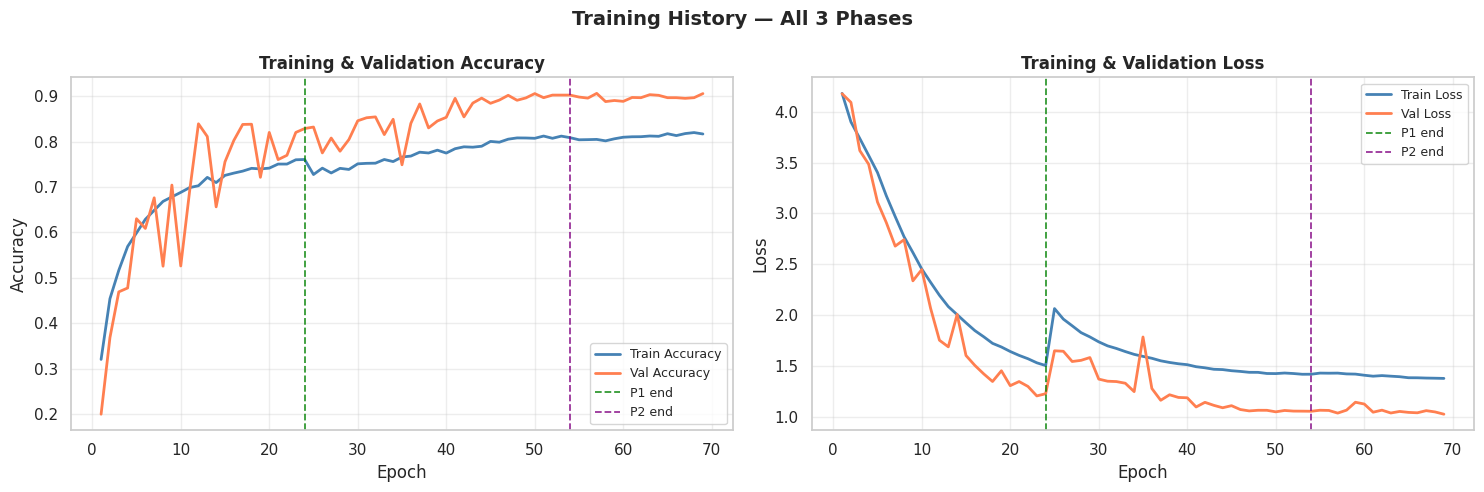

Best Val Accuracy : 0.9060
Best Val Loss     : 1.0240


In [ ]:
# ─── Concatenate all phase histories ─────────────────────────────────────────
def concat_hist(h1, h2, h3, key):
    return h1.history.get(key,[]) + h2.history.get(key,[]) + h3.history.get(key,[])

tr_acc  = concat_hist(history_p1, history_p2, history_p3, "accuracy")
val_acc = concat_hist(history_p1, history_p2, history_p3, "val_accuracy")
tr_loss = concat_hist(history_p1, history_p2, history_p3, "loss")
val_loss= concat_hist(history_p1, history_p2, history_p3, "val_loss")

epochs_all   = range(1, len(tr_acc)+1)
p1_end = len(history_p1.history["accuracy"])
p2_end = p1_end + len(history_p2.history["accuracy"])

fig, axes = plt.subplots(1,2, figsize=(15,5))
for ax,(tr,va,lbl) in zip(axes,[
        (tr_acc,  val_acc,  "Accuracy"),
        (tr_loss, val_loss, "Loss")]):
    ax.plot(epochs_all, tr, lw=2, label=f"Train {lbl}", color="steelblue")
    ax.plot(epochs_all, va, lw=2, label=f"Val {lbl}",   color="coral")
    ax.axvline(p1_end, color="green",  ls="--", lw=1.3, alpha=0.8, label="P1 end")
    ax.axvline(p2_end, color="purple", ls="--", lw=1.3, alpha=0.8, label="P2 end")
    ax.set_xlabel("Epoch"); ax.set_ylabel(lbl)
    ax.set_title(f"Training & Validation {lbl}", fontsize=12, fontweight="bold")
    ax.legend(fontsize=9); ax.grid(alpha=0.35)

plt.suptitle("Training History — All 3 Phases", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("training_curves.png", dpi=150, bbox_inches="tight"); plt.show()
print(f"Best Val Accuracy : {max(val_acc):.4f}")
print(f"Best Val Loss     : {min(val_loss):.4f}")


> **Interpretation.** Phase 1 (high learning rate with warmup) reached 83.9 % validation accuracy at epoch 12 before early stopping at epoch 24. Phase 2 lifted it to **90.55 %** (epoch 26), and Phase 3 added only a marginal gain to a best of **90.60 %**, showing the model had converged. Training accuracy stays below validation accuracy throughout because MixUp, CutMix and label smoothing make the training batches deliberately harder, not because of underfitting.

---

[← Model Design: DeepSceneNet](03_model_architecture.ipynb) · [Next: Evaluation, Error Analysis & Grad-CAM →](05_evaluation_and_explainability.ipynb)